# Pytorch WorkFlow 

Let's explore an example PyTorch end-to-end workflow

## Resources:

   * Book - https://www.learnpytorch.io/01_pytorch_workflow/

In [1]:
what_were_covering = {1: "data (prepare and load)",
    2: "build model",
    3: "fitting the model to data (training)",
    4: "making predictions and evaluating a model (inference)",
    5: "saving and loading a model",
    6: "putting it all together"
}

## Import Libraries 

In [26]:
import torch
import torch.nn as nn
import torch.optim as optim 

import matplotlib.pyplot as plt


torch.__version__


'2.14.1+cu130'

## 1. Data (preparing and loading)

Data can be almost anything... in machine learning.

* Excel speadsheet
* Images of any kind 
* Videos (YouTube has lots of data...)
* Audio like songs or podcasts 
* DNA 
* Text 

Machine learning is a game of two parts:

    1. Turn your data, whatever it is, into numbers (a representation).
    2. Pick or build a model to learn the representation as best as possible.

use linear regression `y = a + bX` to create the data with known parameters (things that can be learned by a model) and then we'll use PyTorch to see if we can build model to estimate these parameters using gradient descent.


In [3]:
# Create *known* parameters
weight = 0.7
bias = 0.3

# Create data
start = 0
end = 1
step = 0.02
X = torch.arange(start, end, step).unsqueeze(dim=1)
y = weight * X + bias   

X[:10], y[:10]

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

In [4]:
len(X), len(y)

(50, 50)

In [5]:
# Create train/test split (one of the most important concepts in machine learning in general)

train_split = int(0.8 * len(X))

x_train, y_train = X[:train_split], y[:train_split]
x_test, y_test = X[train_split:], y[train_split:]


len(x_train), len(y_train), len(x_test), len(y_test)

(40, 40, 10, 10)

### Visualize

In [17]:
def predictions(train_data=x_train,
                train_labels=y_train,
                test_data=x_test,
                test_labels=y_test,
                predictions= None):
    """
    Plots training data, test data and compares predictions.
    """

    plt.figure(figsize=(10, 7))

  # Plot training data in blue
    plt.scatter(train_data, train_labels, c="r", s=6, label="Training data")
  
  # Plot test data in green
    plt.scatter(test_data, test_labels, c="b", s=6, label="Testing data")

    if predictions is not None:
    # Plot the predictions in red (predictions were made on the test data)
        plt.scatter(test_data, predictions, c="g", s=6, label="Predictions")

  # Show the legend
    plt.legend(prop={"size": 14});
     

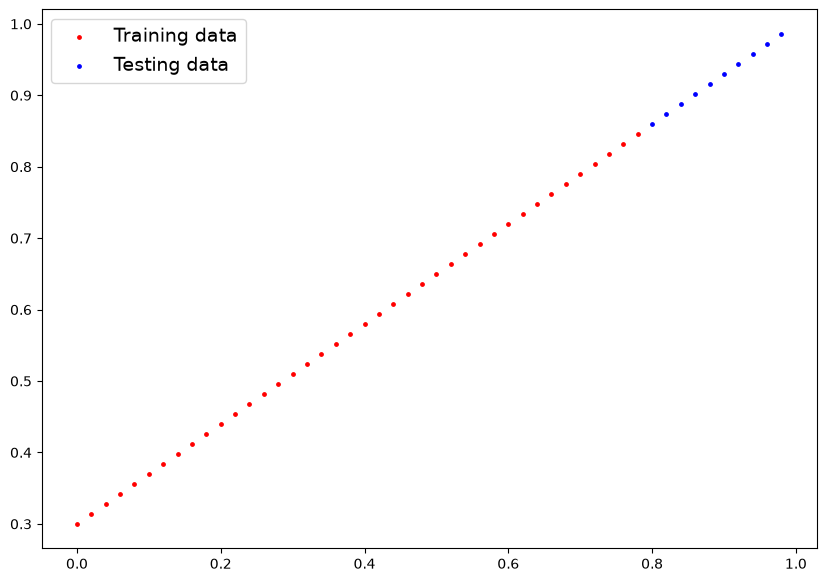

In [18]:
predictions()

## Build Model 

Our first linear regression Model!! Using python

In [19]:
class LinearRegression(nn.Module):
    def __init__(self):
        super().__init__()
        self.weight = nn.Parameter(torch.rand(1, 
                                               requires_grad=True,
                                               dtype=torch.float))

        self.bias = nn.Parameter(torch.rand(1, 
                                                requires_grad=True,
                                                dtype=torch.float))

    def forward(self, x:torch.Tensor):
        return self.weight * x + self.bias  # Applying lr formula




### PyTorch module 	What does it do?
* `torch.nn` --> Contains all of the building blocks for computational graphs (essentially a series of computations executed in a particular way).

* `torch.nn.Parameter`--> Stores tensors that can be used with nn.Module. If requires_grad=True gradients (used for updating model parameters via gradient descent) are calculated automatically, this is often referred to as "autograd". in PyTorch, your models should subclass nn.Module. Requires a forward() method be implemented.
* `torch.optim` --> Contains various optimization algorithms (these tell the model parameters stored in nn.Parameter how to best change to improve gradient descent and in turn reduce the loss).
* `def forward()` --> All nn.Module subclasses require a forward() method, this defines the computation that will take place on the data passed to the particular nn.Module (e.g. the linear regression formula above).

### Checking the contents of our PyTorch model 

Now we've created a model, let's see what's inside..

 So we can check our model parameters or what's inside our model using .parameters().

In [20]:
## create a random seed 

torch.manual_seed(42)

#create an instance of the model 

model_0 = LinearRegression()

#Check out the parameters 

list(model_0.parameters())

[Parameter containing:
 tensor([0.8823], requires_grad=True),
 Parameter containing:
 tensor([0.9150], requires_grad=True)]

In [21]:
# List named parameters 
model_0.state_dict()

OrderedDict([('weight', tensor([0.8823])), ('bias', tensor([0.9150]))])

### making prediction using `torch.inference_mode()`

When we pass data to our model, it'll go through the model's forward() method and produce a result using the computation we've defined.

In [ ]:
# make predictions with model 

# with torch.no_gard():

with torch.inference_mode(): # is a context manager in PyTorch that disables gradient tracking and reduces computational overhead when making predictions.
    y_preds = model_0(x_test)


y_preds

tensor([[1.6208],
        [1.6385],
        [1.6561],
        [1.6738],
        [1.6914],
        [1.7090],
        [1.7267],
        [1.7443],
        [1.7620],
        [1.7796]])

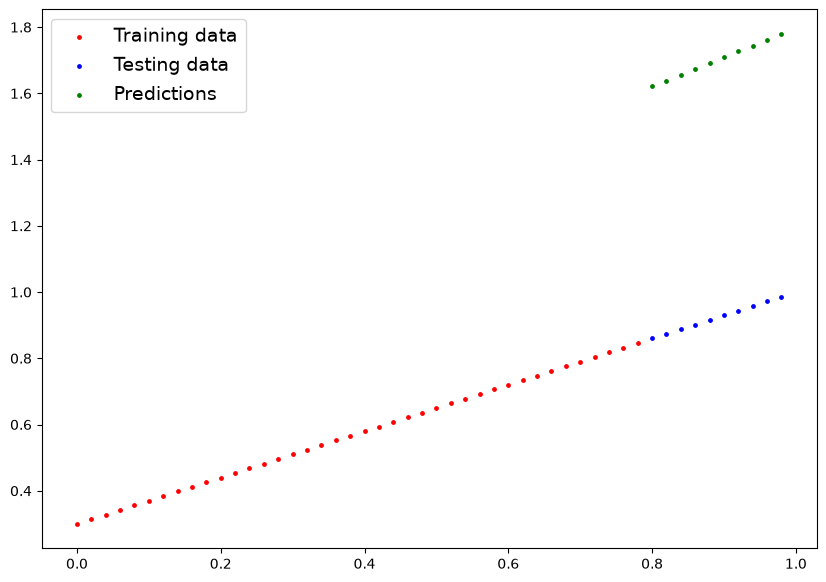

In [23]:
predictions(predictions=y_preds)

In [25]:
model_0.state_dict()

OrderedDict([('weight', tensor([0.8823])), ('bias', tensor([0.9150]))])

In [ ]:
# Setup a loss Function 
loss_fn = nn.L1Loss()

# Setup an optimizer
optimizer = optim.SGD(params=model_0.parameters(), 
                      lr=0.01
                      )